In [1]:
import pandas as pd
import numpy as np
import sys, os, pathlib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
BASE_DIR = Path.cwd().parent

## Dataset pre-processing for classification work with IS
* merge 3 datasets. Drop duplicates
* ensure that 'censored' datapoints are handled appropriately 
* perform dataset splitting and create respective featurisations/embeddings
* save / prep for model training

In [2]:
# import datasets 
DATA_PATH = BASE_DIR / "01_DATASETS"
app = pd.read_csv(DATA_PATH / "APP2024_original.csv")
manner = pd.read_csv(DATA_PATH / "MANNER_IS.csv")
manner.rename(columns={"SMILES_dat": "SMILES"}, inplace=True)

quayle = pd.read_csv(DATA_PATH / "QU_IS.csv")

In [3]:
def add_canon_smiles(df, smiles_col="SMILES"):
    """
    Add a column with canonical SMILES to the dataframe.
    """
    from rdkit import Chem
    df["canonical_SMILES"] = df[smiles_col].apply(lambda x: Chem.MolToSmiles(Chem.MolFromSmiles(x), canonical=True))
    return df

for df in [app, manner, quayle]:
    df = add_canon_smiles(df)

In [4]:
# convert cencored data for quayle
QU_IS_data = quayle["Exp IS (J)"]
QU_IS_data = QU_IS_data.str.replace(r'^[<>]=?', '', regex=True).astype(float)
quayle["Exp IS (J)"] = QU_IS_data

quayle = quayle[["SMILES", "Exp IS (J)", "canonical_SMILES"]].copy()
quayle["Source"] = "QUAYLE"
quayle["Exp IS (J)"].isna().sum()

np.int64(0)

In [5]:
#import g constant
from scipy.constants import g

# clean app dataset
app_IS = app[app["prop"] == "log(h50) exp"].copy()
app_IS["Exp IS (J)"] = app_IS["val"].apply(lambda x: 2.5*g*(10**x)/100) # convert log(h50) to IS in J
app_IS = app_IS[["SMILES", "Exp IS (J)", "canonical_SMILES"]].copy()
app_IS["Source"] = "APPLETON"
app_IS["Exp IS (J)"].isna().sum()

np.int64(0)

In [6]:
# manner 
manner["Exp IS (J)"] = manner["logImpact_J"].apply(lambda x: 10**x)
manner = manner[["SMILES", "Exp IS (J)", "canonical_SMILES"]].copy()
manner["Source"] = "MARRS"
manner["Exp IS (J)"].isna().sum()

np.int64(0)

In [7]:
# Concatenate all datasets, while dropping duplicates based on canonical SMILES
combined_df = pd.concat([app_IS, manner, quayle], ignore_index=True)
original_length = combined_df.shape[0]
combined_df = combined_df.drop_duplicates(subset=['canonical_SMILES']).reset_index(drop=True)
combined_df = combined_df.drop(175, inplace=False).reset_index(drop=True) # Drop. Fails for MACE OFF embedding generation
combined_df.to_csv(DATA_PATH / "combined_IS_dataset.csv", index=False)
print(f"Combined dataset length: {combined_df.shape[0]}")
print(f"Removed duplicates: {original_length - combined_df.shape[0]}")
print(f"Number of missing values in Exp IS (J): {combined_df['Exp IS (J)'].isna().sum()}")

Combined dataset length: 980
Removed duplicates: 1341
Number of missing values in Exp IS (J): 0


## Datalabels for classification

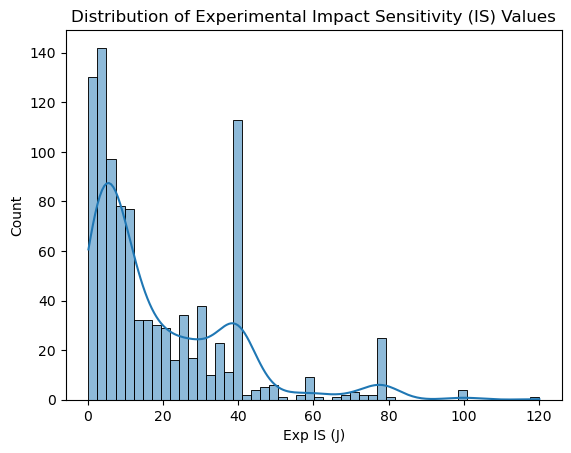

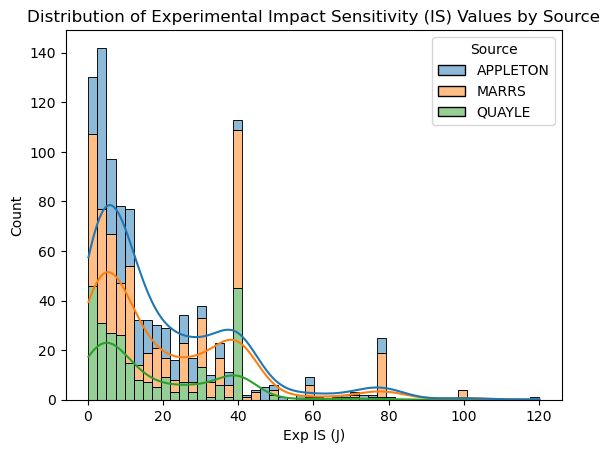

In [8]:
# get distribution of IS values 

sns.histplot(data=combined_df, x="Exp IS (J)", bins=50, kde=True)
plt.title("Distribution of Experimental Impact Sensitivity (IS) Values")
plt.show()

# separate by datasource
sns.histplot(data=combined_df, x="Exp IS (J)", bins=50, hue="Source", multiple="stack", kde=True)
plt.title("Distribution of Experimental Impact Sensitivity (IS) Values by Source")
plt.show() 

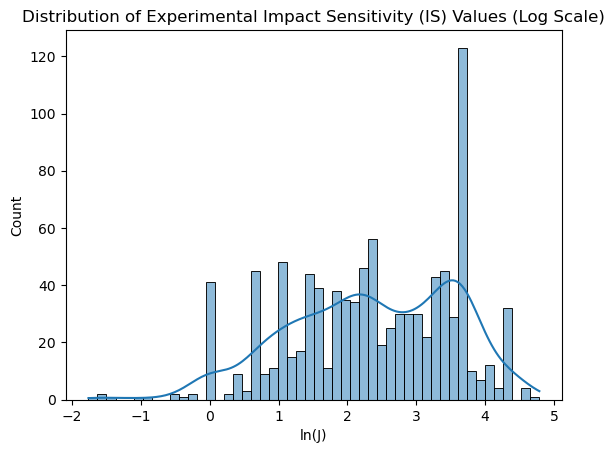

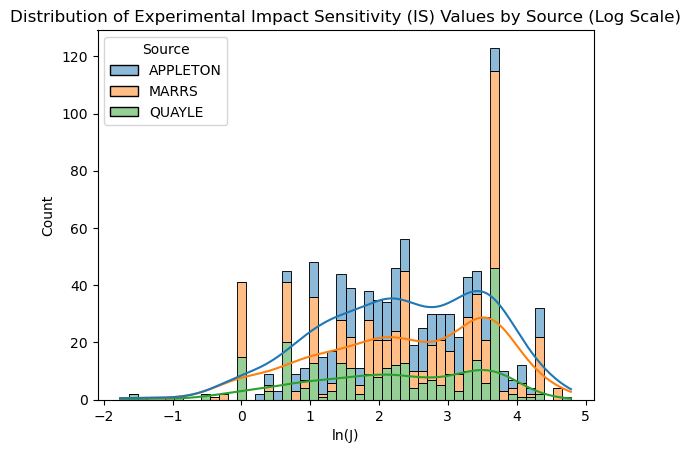

In [9]:
combined_df["ln(J)"] = np.log(combined_df["Exp IS (J)"])

# repeat both of the plots but with log scale on x-axis
sns.histplot(data=combined_df, x="ln(J)", bins=50, kde=True)
plt.title("Distribution of Experimental Impact Sensitivity (IS) Values (Log Scale)")
plt.show()  

sns.histplot(data=combined_df, x="ln(J)", bins=50, hue="Source", multiple="stack", kde=True)
plt.title("Distribution of Experimental Impact Sensitivity (IS) Values by Source (Log Scale)")
plt.show()

# Set data labels

Using the same cutoffs as in [the paper](https://pubs-rsc-org.eux.idm.oclc.org/dd/article/4/11/3260/312862/Understanding-impact-sensitivity-of-energetic)

In [10]:
# set binary classification threshold
threshold = 8 # J
combined_df["binary"] = (combined_df["Exp IS (J)"] > threshold).astype(int)

#count the number of samples in each class
class_counts = combined_df["binary"].value_counts()
print(f"Number of samples in class 0 (IS <= {threshold} J): {class_counts[0]}")
print(f"Number of samples in class 1 (IS > {threshold} J): {class_counts[1]}")
print(f"Number of missing values in binary classification: {combined_df['binary'].isna().sum()}")

Number of samples in class 0 (IS <= 8 J): 392
Number of samples in class 1 (IS > 8 J): 588
Number of missing values in binary classification: 0


In [11]:
# Tertiary classification based on thresholds
cutoffs = [6, 20]  # Define the cutoffs for low, medium, and high
combined_df["tertiary"] = pd.cut(combined_df["Exp IS (J)"], bins=[-np.inf] + cutoffs + [np.inf], labels=[0, 1, 2])

# count the number of samples in each tertiary class
tertiary_class_counts = combined_df["tertiary"].value_counts().sort_index()
print(f"Number of samples in class 0 (IS <= {cutoffs[0]} J): {tertiary_class_counts[0]}")
print(f"Number of samples in class 1 ({cutoffs[0]} J < IS <= {cutoffs[1]} J): {tertiary_class_counts[1]}")
print(f"Number of samples in class 2 (IS > {cutoffs[1]} J): {tertiary_class_counts[2]}")
print(f"Number of missing values in tertiary classification: {combined_df['tertiary'].isna().sum()}")

Number of samples in class 0 (IS <= 6 J): 323
Number of samples in class 1 (6 J < IS <= 20 J): 311
Number of samples in class 2 (IS > 20 J): 346
Number of missing values in tertiary classification: 0


In [12]:
# Quaternary classification based on thresholds
quaternary_cutoffs = [4, 10, 30]  # Define the cutoffs for low, medium, high, and very high
combined_df["quaternary"] = pd.cut(combined_df["Exp IS (J)"], bins=[-np.inf] + quaternary_cutoffs + [np.inf], labels=[0, 1, 2, 3])

# count the number of samples in each quaternary class
quaternary_class_counts = combined_df["quaternary"].value_counts().sort_index()
print(f"Number of samples in class 0 (IS <= {quaternary_cutoffs[0]} J): {quaternary_class_counts[0]}")
print(f"Number of samples in class 1 ({quaternary_cutoffs[0]} J < IS <= {quaternary_cutoffs[1]} J): {quaternary_class_counts[1]}")
print(f"Number of samples in class 2 ({quaternary_cutoffs[1]} J < IS <= {quaternary_cutoffs[2]} J): {quaternary_class_counts[2]}")
print(f"Number of samples in class 3 (IS > {quaternary_cutoffs[2]} J): {quaternary_class_counts[3]}")
print(f"Number of missing values in quaternary classification: {combined_df['quaternary'].isna().sum()}")

Number of samples in class 0 (IS <= 4 J): 235
Number of samples in class 1 (4 J < IS <= 10 J): 257
Number of samples in class 2 (10 J < IS <= 30 J): 255
Number of samples in class 3 (IS > 30 J): 233
Number of missing values in quaternary classification: 0


In [13]:
# Quinary classification based on thresholds
quinary_cutoffs = [3, 8, 18, 40]  # Define the cutoffs for five classes
combined_df["quinary"] = pd.cut(combined_df["Exp IS (J)"], bins=[-np.inf] + quinary_cutoffs + [np.inf], labels=[0, 1, 2, 3, 4])

# count the number of samples in each quinary class
quinary_class_counts = combined_df["quinary"].value_counts().sort_index()
print(f"Number of samples in class 0 (IS <= {quinary_cutoffs[0]} J): {quinary_class_counts[0]}")
print(f"Number of samples in class 1 ({quinary_cutoffs[0]} J < IS <= {quinary_cutoffs[1]} J): {quinary_class_counts[1]}")
print(f"Number of samples in class 2 ({quinary_cutoffs[1]} J < IS <= {quinary_cutoffs[2]} J): {quinary_class_counts[2]}")
print(f"Number of samples in class 3 ({quinary_cutoffs[2]} J < IS <= {quinary_cutoffs[3]} J): {quinary_class_counts[3]}")
print(f"Number of samples in class 4 (IS > {quinary_cutoffs[3]} J): {quinary_class_counts[4]}")

Number of samples in class 0 (IS <= 3 J): 179
Number of samples in class 1 (3 J < IS <= 8 J): 213
Number of samples in class 2 (8 J < IS <= 18 J): 208
Number of samples in class 3 (18 J < IS <= 40 J): 308
Number of samples in class 4 (IS > 40 J): 72


In [14]:
# Save the processed dataset to a CSV file
output_path = BASE_DIR / "08_CLASSIFICATION" / "01_DATASETS" / "combined_IS_dataset.csv"
combined_df.to_csv(output_path, index=False)

In [15]:
combined_df.columns

Index(['SMILES', 'Exp IS (J)', 'canonical_SMILES', 'Source', 'ln(J)', 'binary',
       'tertiary', 'quaternary', 'quinary'],
      dtype='object')

## Generate the datasplits 

In [16]:
# for each of the binary, tertiary, quaternary, and quinary classifications, generate a held-out test set (20% of the data)
# with matched class distributions. Use stratified sampling to ensure that the class distributions in the test set match those in the full dataset.
# Save the indexes of the test set as a numpy array to a file for later use in model evaluation.
# Naming convention: 01_DATASETS/[classification_type]/random_seed[seed]_split_test.npy 

from pathlib import Path

import numpy as np
from sklearn.model_selection import train_test_split

# Ensure saved indices correspond exactly to CSV row positions
combined_df = combined_df.reset_index(drop=True)

classification_types = ["binary", "tertiary", "quaternary", "quinary"]

for seed in range(5):
    for classification_type in classification_types:
        _, test_indices = train_test_split(
            np.arange(len(combined_df)),
            test_size=0.20,
            random_state=seed,
            stratify=combined_df[classification_type],
        )

        output_dir = Path("01_DATASETS") / classification_type
        output_dir.mkdir(parents=True, exist_ok=True)

        output_file = output_dir / f"random_seed{seed}_split_test.npy"
        np.save(output_file, test_indices)

        print(output_file, len(test_indices))

01_DATASETS/binary/random_seed0_split_test.npy 196
01_DATASETS/tertiary/random_seed0_split_test.npy 196
01_DATASETS/quaternary/random_seed0_split_test.npy 196
01_DATASETS/quinary/random_seed0_split_test.npy 196
01_DATASETS/binary/random_seed1_split_test.npy 196
01_DATASETS/tertiary/random_seed1_split_test.npy 196
01_DATASETS/quaternary/random_seed1_split_test.npy 196
01_DATASETS/quinary/random_seed1_split_test.npy 196
01_DATASETS/binary/random_seed2_split_test.npy 196
01_DATASETS/tertiary/random_seed2_split_test.npy 196
01_DATASETS/quaternary/random_seed2_split_test.npy 196
01_DATASETS/quinary/random_seed2_split_test.npy 196
01_DATASETS/binary/random_seed3_split_test.npy 196
01_DATASETS/tertiary/random_seed3_split_test.npy 196
01_DATASETS/quaternary/random_seed3_split_test.npy 196
01_DATASETS/quinary/random_seed3_split_test.npy 196
01_DATASETS/binary/random_seed4_split_test.npy 196
01_DATASETS/tertiary/random_seed4_split_test.npy 196
01_DATASETS/quaternary/random_seed4_split_test.npy 1

# Generate embeddings for the datasets
* need to be rerun vs. regression due to additonal datapoints 

In [17]:
repo_root = Path.cwd().parent.resolve()          # repo root
sys.path.insert(0, str(repo_root))

from modules.chemeleon_embds import chemeleon_embedding
from modules.molclr_embds import mol_clr_embed
from modules.maceoff_embds import generate_maceoff_embedding
from modules.HQ_featureextractor import chemdescriptor

/home/andre/anaconda3/envs/chem/lib/python3.11/site-packages/xgboost/core.py:377: FutureWarning: Your system has an old version of glibc (< 2.28). We will stop supporting Linux distros with glibc older than 2.28 after **May 31, 2025**. Please upgrade to a recent Linux distro (with glibc >= 2.28) to use future versions of XGBoost.
Note: You have installed the 'manylinux2014' variant of XGBoost. Certain features such as GPU algorithms or federated learning are not available. To use these features, please upgrade to a recent Linux distro with glibc 2.28+, and install the 'manylinux_2_28' variant.
  warnings.warn(
/home/andre/anaconda3/envs/chem/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/andre/anaconda3/envs/chem/lib/python3.11/site-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variabl

cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.


#### Morgan Fingerprints (ECFP4)

In [18]:
# Fingerprint generation using RDKit
from rdkit import Chem
from rdkit.Chem import AllChem

def smiles_to_morgan_fp(smiles, fp_gen, n_bits=2048):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(n_bits, dtype=int)
    fp = fp_gen.GetFingerprint(mol)
    arr = np.zeros((n_bits,), dtype=int)
    AllChem.DataStructs.ConvertToNumpyArray(fp, arr)
    return arr


fp_gen = Chem.rdFingerprintGenerator.GetMorganGenerator(2)
fps = combined_df['canonical_SMILES'].apply(lambda s: smiles_to_morgan_fp(s, fp_gen))
# Stack the fingerprint arrays into a 2D array
fps_matrix = np.vstack(fps.values)
np.save(os.path.join("02_EMBEDDINGS", "morgan_fps_embeddings.npy"), fps_matrix)

#### Hand-crafted descriptors (Quayle)

In [19]:
base_dir = f"02_EMBEDDINGS/"
# hand-crafted descriptor generation
rows = [chemdescriptor(smiles) for smiles in combined_df["canonical_SMILES"].values]
arr = pd.DataFrame(rows).to_numpy()
np.save(os.path.join(base_dir, "hq_descriptor_embeddings.npy"), arr)

#### Foundation model embeddings

In [20]:
def safe_save_npy(path, arr):
    try:
        np.save(path, np.asarray(arr))
    except ValueError as e:
        print(f"[WARN] np.save failed for {path}: {e}")
        fallback = path.replace(".npy", ".object.npy")
        np.save(fallback, np.array(arr, dtype=object), allow_pickle=True)
        print(f"[WARN] Saved ragged data as object array: {fallback}")

def generate_and_save_embeddings(smiles_list, save_dir="02_EMBEDDINGS"):
    save_dir = os.path.join(save_dir)
    os.makedirs(save_dir, exist_ok=True)

    #CheMeleon
    chemeleon_emb = chemeleon_embedding(smiles_list, None, ckpt_path="../04_FM_CPS/chemeleon_mp.pt")
    safe_save_npy(os.path.join(save_dir, "chemeleon_embeddings.npy"), chemeleon_emb)

    # MolCLR
    molclr_emb = mol_clr_embed(smiles_list, ckpt_path="04_FM_CPS/MolCLR/ckpt/pretrained_gin/checkpoints/model.pth")
    molclr_emb = molclr_emb.numpy()
    safe_save_npy(os.path.join(save_dir, "molclr_embeddings.npy"), molclr_emb)

    # Mace off large
    maceoff_emb, failed_mols = generate_maceoff_embedding(smiles_list, model_size="large", num_confs=1)
    safe_save_npy(os.path.join(save_dir, "maceoff_large_embeddings.npy"), maceoff_emb)
    print(f"Failed molecules for (large): {failed_mols}")

    return {
        "chemeleon": chemeleon_emb,
        "molclr": molclr_emb,
        "maceoff": maceoff_emb
    }
embds = generate_and_save_embeddings(combined_df["canonical_SMILES"].values)

/home/andre/01_FOUNDATION_MODELS/modules/chemeleon_embds.py:50: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(ckpt_path, map_location="cpu")
Generating CheMeleon embeddings:  12%|█▎        | 2/16 [00:02<00:14,  1.07s/it]


KeyboardInterrupt: 